In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
from PIL import Image


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import PaP_plotting_func
importlib.reload(PaP_plotting_func)
from PaP_plotting_func import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_func import *
import AR_interpolations_func
importlib.reload(AR_interpolations_func)
from AR_interpolations_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation')
from AR_interpolations_plotting import *
import AR_interpolations_plotting
importlib.reload(AR_interpolations_plotting)
from AR_interpolations_plotting  import *




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_plot
importlib.reload(PaP_quantitative_study_plot)
from PaP_quantitative_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\PaP_calculate_quantitative_signal')
import PaP_quantitative_study_func
importlib.reload(PaP_quantitative_study_func)
from PaP_quantitative_study_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

from Spectra_plotting import *
import Spectra_plotting
importlib.reload(Spectra_plotting)
from Spectra_plotting  import *


import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches

import matplotlib.animation as animation


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Illustrations')
import gif_func
importlib.reload(gif_func)
from gif_func import *



import matplotlib as mpl
mpl.rcParams["font.size"] = 18

dir_save_data = r'C:\Users\nberr\Desktop\Conference\RJP 2025\Figures'

## Gifs

### SPR moving acoustic

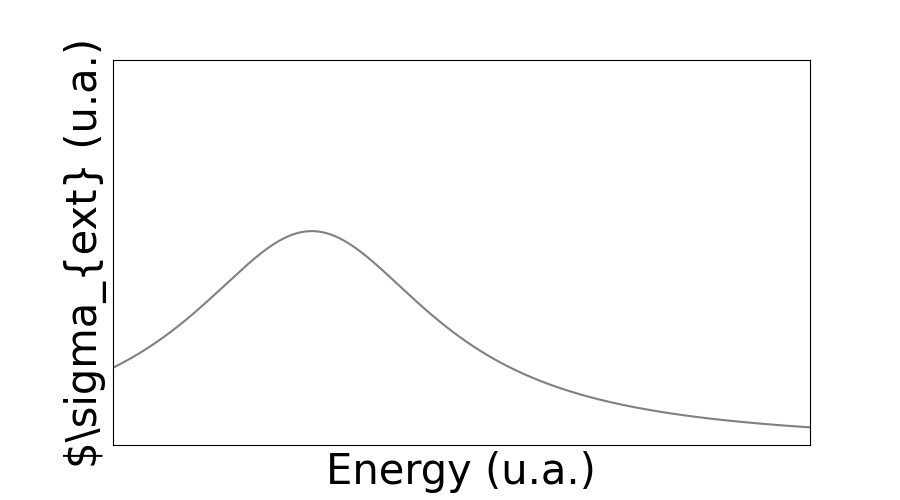

In [34]:
animation_name = 'SPR_acoustic'

mpl.rcParams["font.size"] = 30

fig, ax = plt.subplots(figsize=(9,5))


imax=100

#Set (x,y) limits for axes
xmin_spr, xmax_spr = (1.8,  2.5)

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -0.7, 0.7

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.05
delta_w = 0
delta_Ec = -0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0



ax.set_xlim((xmin_spr, xmax_spr))
ax.set_ylim((ymin_spr, ymax_spr))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('Energy (u.a.)')
ax.set_ylabel(r'$\sigma_{ext} (u.a.)')




scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')




Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax.cla()
    #x_probe = Energy[600]


    ### SPR plot 
    ax.set_xlim((xmin_spr, xmax_spr))
    ax.set_ylim((ymin_spr, ymax_spr))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Energy ')
    ax.set_ylabel(r'$\sigma_{ext}$')

    width, height = 0.2, 0.1
    x_ini, y_ini = 0.15 - width/2, 0.85 - height/2
    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)

    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax.transAxes, facecolor='#ffc507ff', edgecolor='black')
    ax.add_patch(rect_disk)

    scat = ax.plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    #ax.plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

   
    #ax.axvline(x_probe, color='green', linestyle='--',zorder=0)
    #ax.text(0.63, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax.transAxes)




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

### SPR and DTT acoustic

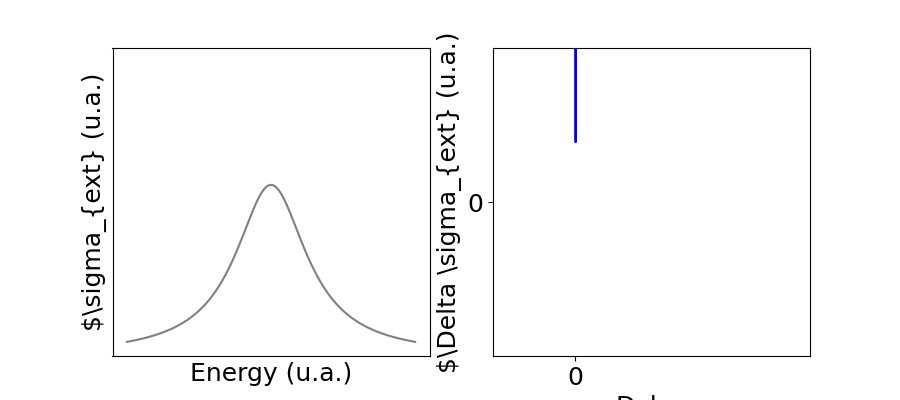

In [ ]:
animation_name = 'SPR_and_DTT_signal_acoustic'

fig, ax = plt.subplots(ncols=2, figsize=(9,4))


imax=100

#Set (x,y) limits for axes

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -0.7, 0.7

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.05
delta_w = 0
delta_Ec = 0.03

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0




ax[0].set_ylim((ymin_spr, ymax_spr))
ax[0].set_xticks([])  # Remove x-axis ticks
ax[0].set_yticks([])  # Remove y-axis ticks
ax[0].set_xlabel('Energy (u.a.)')
ax[0].set_ylabel(r'$\sigma_{ext} (u.a.)')


ax[1].set_ylim((ymin_dtt, ymax_dtt))
ax[1].set_xlim((xmin_dtt, xmax_dtt))
ax[1].set_xticks([0])  # Remove x-axis ticks
ax[1].set_yticks([0])  # Remove y-axis ticks
ax[1].set_xlabel('Delay')
ax[1].set_ylabel(r'$\Delta \sigma_{ext} (u.a.)')


scat = ax[0].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')

scat = ax[1].plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='blue')



Colors= list(Color("red").range_to(Color("yellow"),imax))



def animate_lorentz(i) :
    ax[1].cla()
    ax[0].cla()
    x_probe = Energy[600]


    ### SPR plot 

    ax[0].set_ylim((ymin_spr, ymax_spr))
    ax[0].set_xticks([])  # Remove x-axis ticks
    ax[0].set_yticks([])  # Remove y-axis ticks
    ax[0].set_xlabel('Energy ')
    ax[0].set_ylabel(r'$\sigma_{ext}$')

    width, height = 0.2, 0.1
    x_ini, y_ini = 0.15 - width/2, 0.85 - height/2
    x_c, y_c = x_ini - width/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi), y_ini - height/2*np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)

    rect_disk = mpatches.Rectangle((x_c, y_c), 0.2*(1+ np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi) ), 0.1*(1+np.array(Time>0)[i]*Osc1(Time[i], alpha, tau, T, phi)), transform=ax[0].transAxes, facecolor='#ffc507ff', edgecolor='black')
    ax[0].add_patch(rect_disk)

    scat = ax[0].plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*Osc1(Time[i], delta_Ec, tau, T, phi), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0),color='blue')
    ax[0].plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)
    ax[0].plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(Osc1(Time[i], delta_Ec, tau, T, phi)), w + np.array(Time>0)[i]*Osc1(Time[i], delta_w, tau, T, phi), A, y0)], color='green')

   
    ax[0].axvline(x_probe, color='green', linestyle='--',zorder=0)
    ax[0].text(0.63, 0.8, r'$\lambda_\mathrm{probe}$', color='green',  transform=ax[0].transAxes)


    ## DTT plot
    ax[1].set_ylim((ymin_dtt, ymax_dtt))
    ax[1].set_xlim((xmin_dtt, xmax_dtt))
    ax[1].set_xticks([0])  # Remove x-axis ticks
    ax[1].set_yticks([0])  # Remove y-axis ticks
    ax[1].set_xlabel('Delay')
    ax[1].set_ylabel(r'$\Delta \sigma_{ext}$')
    ax[1].tick_params(axis='x', direction='in', pad=-20)

    scat = ax[1].plot(Time[:i+1], Lorentz(x_probe, E_c+np.array(Time>0)[:i+1]*(Osc1(Time[:i+1], delta_Ec, tau, T, phi)), w + np.array(Time>0)[:i+1]*Osc1(Time[:i+1], delta_w, tau, T, phi), A, y0)-Lorentz(x_probe, E_c, w , A, y0),color='black')

 



    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

### SPR Thermic only

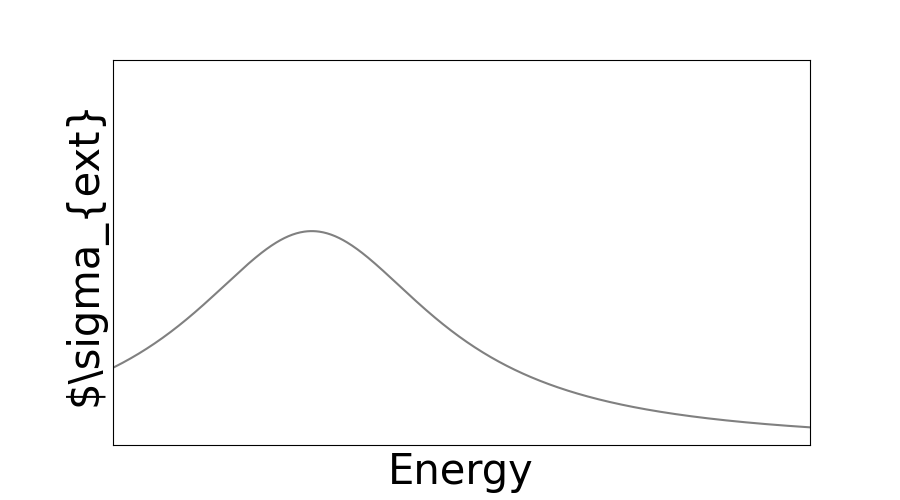

In [18]:
animation_name = 'SPR_thermic'

mpl.rcParams["font.size"] = 30

fig, ax = plt.subplots(figsize=(9,5))


imax=100

#Set (x,y) limits for axes
xmin_spr, xmax_spr = (1.8,  2.5)

ymin_spr, ymax_spr = (0,  6)


xmin_dtt, xmax_dtt = -350, 1000
ymin_dtt, ymax_dtt = -0.7, 0.7

top_lim = 3
bottom_limit  = -0.5



Energy = np.linspace(1.5, 2.5, 1000)
Time = np.linspace(-300, 1000, imax)

delta_w = 0.1
tau = 800/3
delta_Ec = 0.1
delta_Ec=0.002

tau = 800/3
T = 100
phi = 0


#Shape variation of the nanosidk
alpha = 0.2 # Dilatation coefficient


#Lorentzian shape for the SPR
A = 1
E_c = 2
w = 0.3
y0=0



ax.set_xlim((xmin_spr, xmax_spr))
ax.set_ylim((ymin_spr, ymax_spr))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('Energy')
ax.set_ylabel(r'$\sigma_{ext}')




scat = ax.plot(Energy, Lorentz(Energy, E_c, w, A, y0),color='grey')




Colors= list(Color("red").range_to(Color('#ffc507'),imax))



def animate_lorentz(i) :


    ax.cla()


    ### SPR plot 
    index_color = int(imax * (1- np.array(Time>0)[i]*(ExpDec1(Time[i], 1, tau)))-0.001)
    

    
    ax.set_xlim((xmin_spr, xmax_spr))
    ax.set_ylim((ymin_spr, ymax_spr))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('Energy')
    ax.set_ylabel(r'$\sigma_{ext}$')


    width, height = 0.2, 0.1
    x_ini, y_ini = 0.15 - width/2, 0.85 - height/2
    rect_disk = mpatches.Rectangle((x_ini, y_ini), 0.2, 0.1, transform=ax.transAxes, facecolor=Colors[index_color].rgb, edgecolor='black')
    ax.add_patch(rect_disk)

    #rect_sub = mpatches.Rectangle((0.1, 0.7), 0.4, 0.15, transform=ax.transAxes, facecolor="#32ADFF",alpha=1, edgecolor='black')
    #ax.add_patch(rect_sub)
    scat = ax.plot(Energy, Lorentz(Energy, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*(ExpDec1(Time[i], delta_w, tau)), A, y0),color='blue')
    ax.plot(Energy, Lorentz(Energy, E_c, w , A, y0),color='grey', alpha=0.5)

    #ax[0].plot([x_probe, x_probe], [Lorentz(x_probe, E_c, w , A, y0), Lorentz(x_probe, E_c+np.array(Time>0)[i]*(ExpDec1(Time[i], delta_Ec, tau)), w + np.array(Time>0)[i]*ExpDec1(Time[i], delta_w, tau), A, y0)], color='green')



    

    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

## SMS gif

-2.0


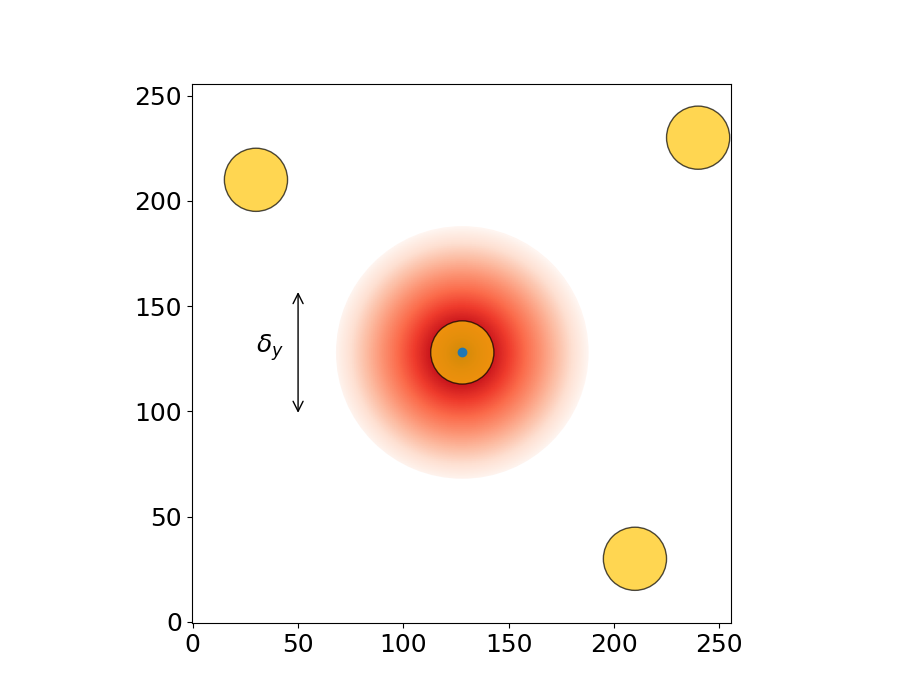

In [ ]:

fig, ax = plt.subplots(figsize=(9,7))




# # Define width and height of image
# W, H = 650, 650

# # Create solid red image
# im = Image.new(mode='RGB', size=(W,H), color=(153,0,0))

# # Create radial alpha/transparency layer. 255 in centre, 0 at edge
# Y = np.linspace(-1, 1, H)[None, :]*255
# X = np.linspace(-1, 1, W)[:, None]*255
# alpha = np.sqrt(X**2 + Y**2)
# alpha = 255 - np.clip(0,255,alpha)
#im.putalpha(Image.fromarray(alpha.astype(np.uint8)))



# img = ax.imshow(np.linspace(0, 1, 256).reshape(-1, 1), cmap='plasma',
#                 extent=[ - 1,  + 1, 0 - 1, 0 + 1], origin='lower')
# circle = plt.Circle((0, 0), 1, transform=ax.transData)
# img.set_clip_path(circle)



x = np.linspace(-0.5, 0.5, 256)
y = np.linspace(-0.5, 0.5, 256)


R_beam = 60
R_ND = 15


x_1, y_1 = 256//2, 256//2

x_2, y_2 = 240, 230

x_3, y_3 = 30, 210

x_4, y_4 = 210, 30


xArray, yArray = np.meshgrid(x, y)
plotArray = 1-3*np.sqrt((xArray)**2 + (yArray)**2)/np.max(np.sqrt((xArray)**2 + (yArray)**2))



cmap = plt.cm.Reds
print(np.min(plotArray))
img= ax.imshow(plotArray,
          cmap=cmap,
          vmin=0,
          vmax=1, origin='lower')


circle = plt.Circle((256//2, 256//2), R_beam, transform=ax.transData, zorder=1)
img.set_clip_path(circle)


circle_disk_1 = mpatches.Circle((x_1, y_1), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_1)

circle_disk_2 = mpatches.Circle((x_2, y_2), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_2)

circle_disk_3 = mpatches.Circle((x_3, y_3), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_3)

circle_disk_4 = mpatches.Circle((x_4, y_4), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_4)


ax.annotate(text='', xy=(50,256//2-30), xytext=(50,256//2 +30), color='red',arrowprops=dict(arrowstyle='<->', color="black"))
ax.text(30, 256//2, r'$\delta_y$')




ax.scatter(x_center, y_center)


plt.show()

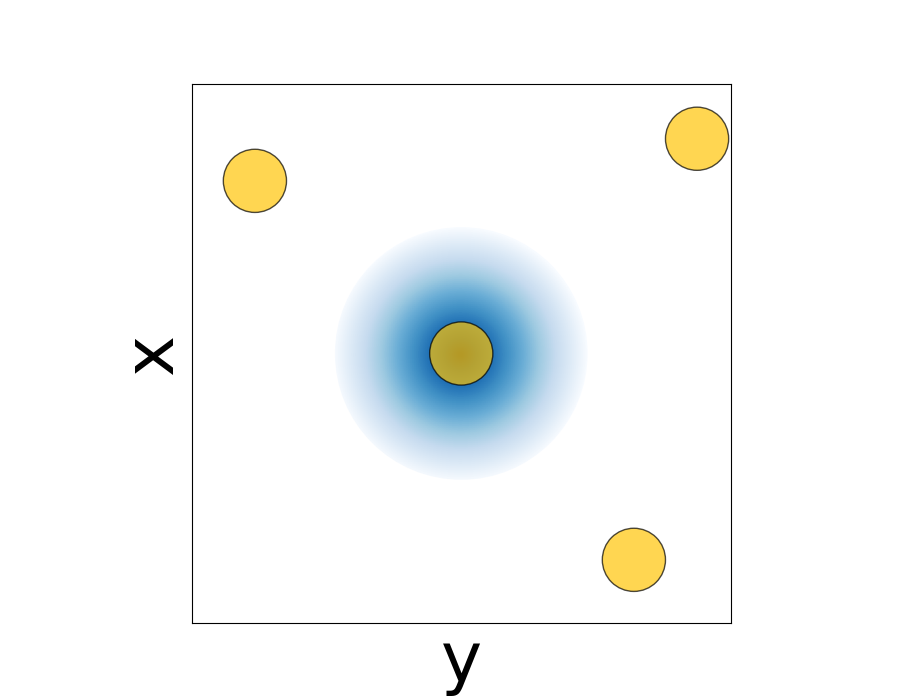

In [25]:
animation_name = 'Animation SMS'

mpl.rcParams["font.size"] = 50

fig, ax = plt.subplots(figsize=(9,7))


imax=100

Time = np.linspace(-300, 1000, imax)

#Set (x,y) limits for axes
xmin, xmax = 0, 256
ymin, ymax = 0, 256



x_1, y_1 = 256//2, 256//2

x_2, y_2 = 240, 230

x_3, y_3 = 30, 210

x_4, y_4 = 210, 30

delta_y =  30 # Modulation amplitude


R_beam = 60
R_ND = 15

xArray, yArray = np.meshgrid(x, y)
plotArray = 1-3*np.sqrt((xArray)**2 + (yArray)**2)/np.max(np.sqrt((xArray)**2 + (yArray)**2))





ND_color= list(Color("red").range_to(Color('#ffc507'),imax))
ND_color = '#ffc507'
Beam_color = "#FF1111"




x = np.linspace(-0.5, 0.5, 256)
y = np.linspace(-0.5, 0.5, 256)

cmap = plt.cm.Blues

img= ax.imshow(plotArray,
          cmap=cmap,
          vmin=0,
          vmax=1, origin='lower')

circle = plt.Circle((x_1, y_1), R_beam, transform=ax.transData)
img.set_clip_path(circle)


circle_disk_1 = mpatches.Circle((x_1, y_1), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_1)

circle_disk_2 = mpatches.Circle((x_2, y_2), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_2)

circle_disk_3 = mpatches.Circle((x_3, y_3), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_3)

circle_disk_4 = mpatches.Circle((x_4, y_4), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
ax.add_patch(circle_disk_4)


ax.set_xlim((xmin, xmax))
ax.set_ylim((ymin, ymax))
ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks
ax.set_xlabel('y')
ax.set_ylabel('x')


def animate_lorentz(i) :


    ax.cla()


    ### SPR plot 


    

    ax.set_xlim((xmin, xmax))
    ax.set_ylim((ymin, ymax))
    ax.set_xticks([])  # Remove x-axis ticks
    ax.set_yticks([])  # Remove y-axis ticks
    ax.set_xlabel('y')
    ax.set_ylabel('x')

    img= ax.imshow(plotArray,
            cmap=cmap,
            vmin=0,
            vmax=1, origin='lower', zorder=0)


    circle = plt.Circle((x_1, y_1), R_beam, transform=ax.transData)
    img.set_clip_path(circle)




    circle_disk_1 = mpatches.Circle((x_1, y_1+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_1)

    circle_disk_2 = mpatches.Circle((x_2, y_2+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_2)

    circle_disk_3 = mpatches.Circle((x_3, y_3+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    ax.add_patch(circle_disk_3)

    circle_disk_4 = mpatches.Circle((x_4, y_4+ delta_y*np.cos(2*np.pi*Time[i]/(Time.max()/6))), R_ND, facecolor='#ffc507', edgecolor='black', zorder=0, alpha=0.7)
    scat = ax.add_patch(circle_disk_4)

    ax.annotate(text='', xy=(200,256//2-30), xytext=(200,256//2 +30),arrowprops=dict(arrowstyle='<->', color="black"))
    ax.text(215, 256//2, r'$\delta_y$')
  




    return(scat,)

#interval=1000//60
ani = animation.FuncAnimation(fig, animate_lorentz, repeat=True, frames=imax, interval = 10)
plt.show()


os.chdir(dir_save_data)

if  1 :
        
    writer = animation.PillowWriter(fps=15,
                                    metadata=dict(artist='Me'),
                                    bitrate=1800)
    ani.save(animation_name + '.gif', writer=writer)

plt.clf()
mpl.rcParams["font.size"] = 18

## Illustration of ensemble measurements

C:\Users\nberr\AppData\Local\Temp\ipykernel_16456\3638183251.py:28: RuntimeWarning:

overflow encountered in divide



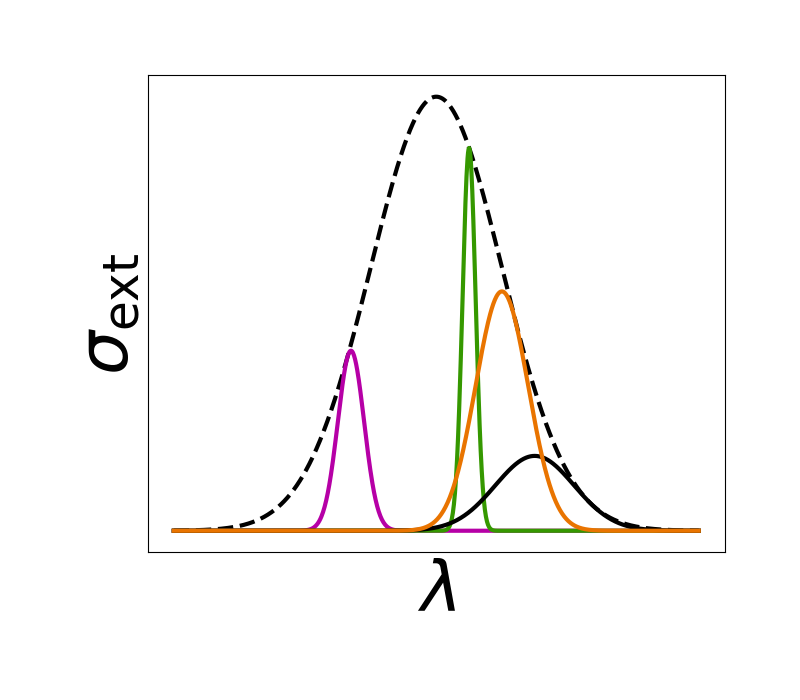

In [32]:
mpl.rcParams["font.size"] = 50
fig, ax = plt.subplots(figsize=(8,7))

# Paramètres de l'enveloppe
mu_env = 0
sigma_env = 1.0
x = np.linspace(-4, 4, 1000)
gauss_env = np.exp(- (x - mu_env)**2 / (2 * sigma_env**2))

# Tracer l'enveloppe noire en pointillés
ax.plot(x, gauss_env, 'k--', label='Enveloppe gaussienne (σ=1)', linewidth=3)

# Paramètres des gaussiennes internes (plus étroites, décentrées)
sigmas = [0.2, 0.1, 0.6, 0.4]
centers = [-1.3, 0.5, 1.5, 1]
colors = ["#B600A6", "#359800", "#000000", "#E97400"]



ax.set_xticks([])  # Remove x-axis ticks
ax.set_yticks([])  # Remove y-axis ticks

for mu, sigma, c in zip(centers, sigmas, colors):
    gauss = np.exp(- (x - mu)**2 / (2 * sigma**2))
    
    # Calcul du facteur de normalisation pour garantir que la courbe est toujours sous l'enveloppe
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = gauss_env / gauss
        ratio = np.where(gauss > 0, ratio, np.inf)  # éviter divisions par zéro
        scale = np.min(ratio)

    gauss_scaled = scale * gauss
    ax.plot(x, gauss_scaled, c = c, label=f'σ={sigma:.2f}, µ={mu:.1f}', linewidth=3)

# Mise en forme

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$\sigma_\mathrm{ext}$')
plt.tight_layout()
plt.show()


os.chdir(dir_save_data)

plt.savefig('Ensemble study plot.svg')

mpl.rcParams["font.size"] = 18